# Week 1 · Lab Workshop
## Build your own generator
*AI for Creativity · Level 6 · work in pairs*

**Your brief:** turn today's poem-and-palette code into a **themed generator for your own discipline** — for example a fashion slogan generator, a film-title generator, a perfume-name generator, a game-item generator, or a café-menu poet.

| Track | What you do |
|---|---|
| 🟢 **Core** | Replace every `FILL_ME` and edit the word lists and colour rules |
| 🔵 **Stretch** | Add a function and a `while` loop so a user types a *mood* and gets a matching poem and palette |

At the end: **gallery walk** — every pair shows its best output on screen. Save your poster for your R&D journal.

**How to use this notebook**

- Works in **Google Colab** (open via *File → Upload notebook*) and in **Jupyter Notebook / JupyterLab** (Anaconda).
- Run a cell with **Shift + Enter**. Run cells **top to bottom** — later cells use things made in earlier ones.
- Grey text starting with `#` is a *comment*: a note for humans. Python ignores it.
- Broke something? *Runtime → Restart* (Colab) or *Kernel → Restart* (Jupyter) and run from the top. You cannot break the computer.

---
## 🟢 Core · Step 1 — Choose a theme
Replace `FILL_ME` with your theme in quotes, e.g. `"perfume names"`.

In [1]:
import random
import matplotlib.pyplot as plt

theme = "Superhero names"
print(f"Today I am building a generator for: {theme}")

Today I am building a generator for: Superhero names


## 🟢 Core · Step 2 — Build your word banks
Write **at least 5 items** in each list. Think like a copywriter or poet in your field.

In [2]:
part_a = ["Bouncing", "Flaming", "Tuffest", "Flashiest", "Sparkling", "Youngest"] # Adjectives for the hero
part_b = ["Man", "Woman", "Attack Helicopter", "Watchdog", "Chucklenut"] # What they are
part_c = ["Everrr", "of the End", "in the Summer", "of all of history", "who frew up"] # Another description of them

## 🟢 Core · Step 3 — Generate 10 ideas with a loop

In [3]:
for i in range(10): # how many ideas? 10!
    idea = f"{random.choice(part_a)} {random.choice(part_b)} {random.choice(part_c)}"
    print(f"{i + 1}. {idea}")

1. Sparkling Chucklenut of the End
2. Flaming Woman in the Summer
3. Flashiest Watchdog who frew up
4. Flaming Woman Everrr
5. Flashiest Man of all of history
6. Flaming Man who frew up
7. Tuffest Chucklenut of all of history
8. Bouncing Chucklenut in the Summer
9. Sparkling Man of all of history
10. Youngest Woman of all of history


## 🟢 Core · Step 4 — A palette that matches your theme
Set the **minimum and maximum** for red, green and blue (0–255). Cool/ocean → high blue. Earthy → medium red and green, low blue. Neon → push one channel to 255.

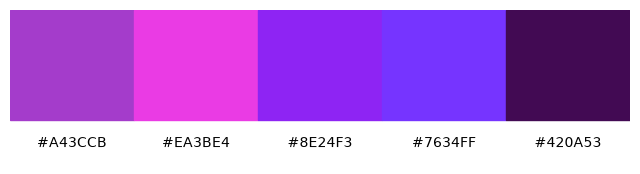

In [4]:
def theme_colour():
    """The colors range from strong reds to blues,
    and occasionally magentas in between"""
    r = random.randint(64, 255)
    g = random.randint(0, 64)
    b = random.randint(64, 255)
    return f"#{r:02X}{g:02X}{b:02X}"

palette = [theme_colour() for _ in range(5)]

fig, ax = plt.subplots(figsize=(8, 2))
for i, c in enumerate(palette):
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=c))
    ax.text(i + 0.5, -0.15, c, ha="center", va="top")
ax.set_xlim(0, 5); ax.set_ylim(-0.4, 1); ax.axis("off")
plt.show()

## 🟢 Core · Step 5 — Make a poster for the gallery walk

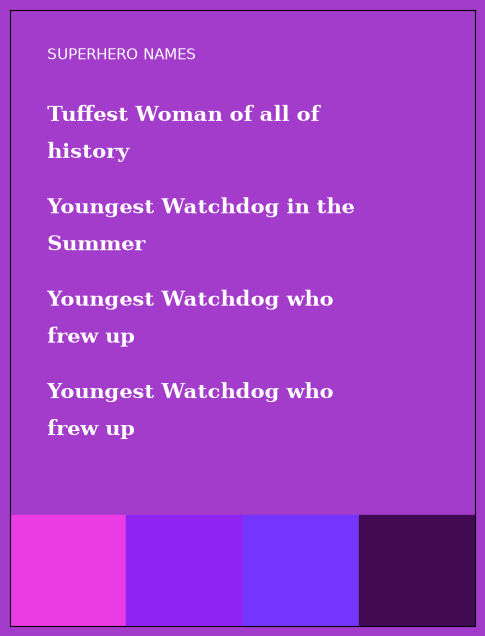

In [5]:
ideas = [f"{random.choice(part_a)} {random.choice(part_b)} {random.choice(part_c)}" for _ in range(4)]

import textwrap
fig, ax = plt.subplots(figsize=(6, 8), facecolor=palette[0])
ax.set_facecolor(palette[0])
for i, c in enumerate(palette[1:]):
    ax.add_patch(plt.Rectangle((i * 0.25, 0), 0.25, 0.18, color=c))
ax.text(0.08, 0.92, theme.upper(), fontsize=11, color="white")
y = 0.82
for line in ideas:
    for part in textwrap.wrap(line, 24):          # wrap long lines so they fit
        ax.text(0.08, y, part, fontsize=15, color="white", fontweight="bold", family="serif")
        y -= 0.06
    y -= 0.03
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([]); ax.set_yticks([])
fig.savefig("week1_poster.png", dpi=150, bbox_inches="tight")
plt.show()

✅ **Core done!** Download `week1_poster.png` for your R&D journal. Write 2–3 sentences: *What rules did you design? What surprised you?*

---
## 🔵 Stretch · A mood-driven generator
Goal: the user types a mood (`calm`, `angry`, `joyful`…) and gets words **and** colours that match.

**Hints**
1. Make a **dictionary** that maps each mood to its own word list and colour ranges.
2. Write a function `generate(mood)` that returns a poem and a palette.
3. Use a `while` loop with `input()` so the user can keep asking until they type `quit`.

Enter a mood: calm


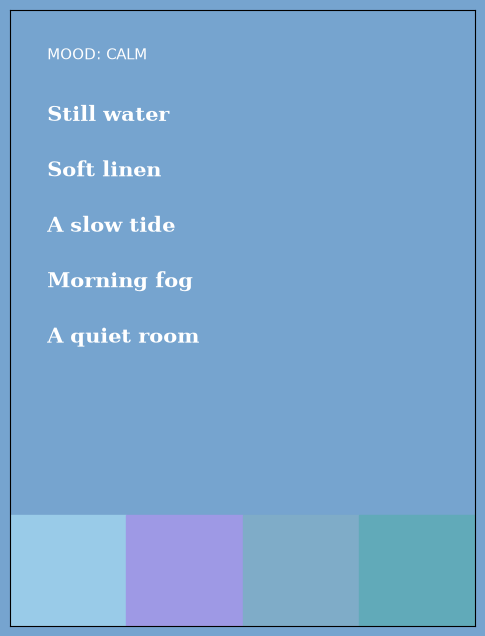

In [12]:
moods = {
    "calm": {
        "name": "calm",
        "words": [
            "still water",
            "soft linen",
            "a slow tide",
            "morning fog",
            "a quiet room"
        ],
        "rgb":   [(80, 160), (140, 210), (180, 255)], #
    },
    "silly": {
        "name": "silly",
        "words": [
            "funny",
            "goofy",
            "pinwheel",
            "giant lollipop",
            "bubble blower",
            "dum"
        ],
        "rgb": [(160, 255), (160, 255), (0, 96)]
    },
    "angry": {
        "name": "angry",
        "words": [
            "firey",
            "rageful",
            "slow walkers",
            "charger wasn't plugged in",
            "line skippers"
        ],
        "rgb": [(192, 255), (32, 192), (0, 64)]
    }
}

def random_color(color_params):
    # Accesses the min and max value of each color parameter
    r = random.randint(color_params[0][0], color_params[0][1])
    g = random.randint(color_params[1][0], color_params[1][1])
    b = random.randint(color_params[2][0], color_params[2][1])
    return f"#{r:02X}{g:02X}{b:02X}"

def generate(mood: dict):
    """Generate a poster using the mood passed onto the function"""

    # Generate 5 colors
    mood_colors = []
    for _ in range(5):
      mood_colors.append(random_color(mood["rgb"]))

    # Figure size
    fig, ax = plt.subplots(
        figsize=(6, 8),
        facecolor=mood_colors[0]
    )

    # First generated colors serves as the background
    ax.set_facecolor(mood_colors[0])

    # Blocks at the bottom displaying the 4 other colors
    for i, c in enumerate(mood_colors[1:]):
        ax.add_patch(plt.Rectangle((i * 0.25, 0), 0.25, 0.18, color=c))
    ax.text(0.08, 0.92, f"MOOD: {mood["name"].upper()}", fontsize=11, color="white")
    y = 0.82

    # Generate word lines, taken from the prior poem function, just rearranged
    # the parameters
    for word in mood["words"]:
        for part in textwrap.wrap(str(word).capitalize(), 24):
            ax.text(0.08, y, part, fontsize=15, color="white", fontweight="bold", family="serif")
            y -= 0.06
        y -= 0.03
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([]); ax.set_yticks([])
    fig.savefig(f"{mood["name"]}_poster.png", dpi=150, bbox_inches="tight")
    plt.show()


def main():
    while True:
        mood = input("Enter a mood:").lower()
        if mood in moods.keys():
            generate(moods[mood])
            return
        elif mood == "":
            return
        else:
            print("We don't have that mood")

if __name__ == "__main__":
    main()


**Extra stretch ideas:** add an unknown-mood message using `if mood not in moods:` · save a poster per mood · generate a *haiku* by counting syllables in each word list.